# 01 — Data exploration

This notebook documents the MedIMeta pediatric pneumonia dataset, the official splits, and the fixed 25% training subset. It is intentionally read-only: it does not train a model or touch the test labels for model selection.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: C:\Users\DAR\Desktop\Pneumonia_classification\p06-pneumonia-limited-data


## Dataset and splits

MedIMeta task `disease class` has three labels: NORMAL, BACTERIA, VIRUS. The official train/val/test split files are used unchanged. The main experiments train on a fixed 25% stratified sample of the official training split (seed 42).

In [2]:
from src.utils import load_config
from src.analysis import explore_data

config = load_config("configs/base.yaml")
explore_data(config)

Class distribution summary:
       set    class  count  proportion
full_train   NORMAL   1161    0.262967
full_train BACTERIA   2107    0.477237
full_train    VIRUS   1147    0.259796
   train25   NORMAL    290    0.262919
   train25 BACTERIA    526    0.476881
   train25    VIRUS    287    0.260199
       val   NORMAL    188    0.230110
       val BACTERIA    431    0.527540
       val    VIRUS    198    0.242350
      test   NORMAL    234    0.375000
      test BACTERIA    242    0.387821
      test    VIRUS    148    0.237179


`explore_data` writes `results/figures/class_distribution.{png,csv,json}` and `results/figures/samples_by_class.png`, and prints the class counts.

In [3]:
import pandas as pd
pd.read_csv("results/figures/class_distribution.csv")

Out[0]: 
           set     class  count  proportion
0   full_train    NORMAL   1161    0.262967
1   full_train  BACTERIA   2107    0.477237
2   full_train     VIRUS   1147    0.259796
3      train25    NORMAL    290    0.262919
4      train25  BACTERIA    526    0.476881
5      train25     VIRUS    287    0.260199
6          val    NORMAL    188    0.230110
7          val  BACTERIA    431    0.527540
8          val     VIRUS    198    0.242350
9         test    NORMAL    234    0.375000
10        test  BACTERIA    242    0.387821
11        test     VIRUS    148    0.237179


,set,class,count,proportion
0,full_train,NORMAL,1161,0.262967
1,full_train,BACTERIA,2107,0.477237
2,full_train,VIRUS,1147,0.259796
3,train25,NORMAL,290,0.262919
4,train25,BACTERIA,526,0.476881
5,train25,VIRUS,287,0.260199
6,val,NORMAL,188,0.230110
7,val,BACTERIA,431,0.527540
8,val,VIRUS,198,0.242350
9,test,NORMAL,234,0.375000


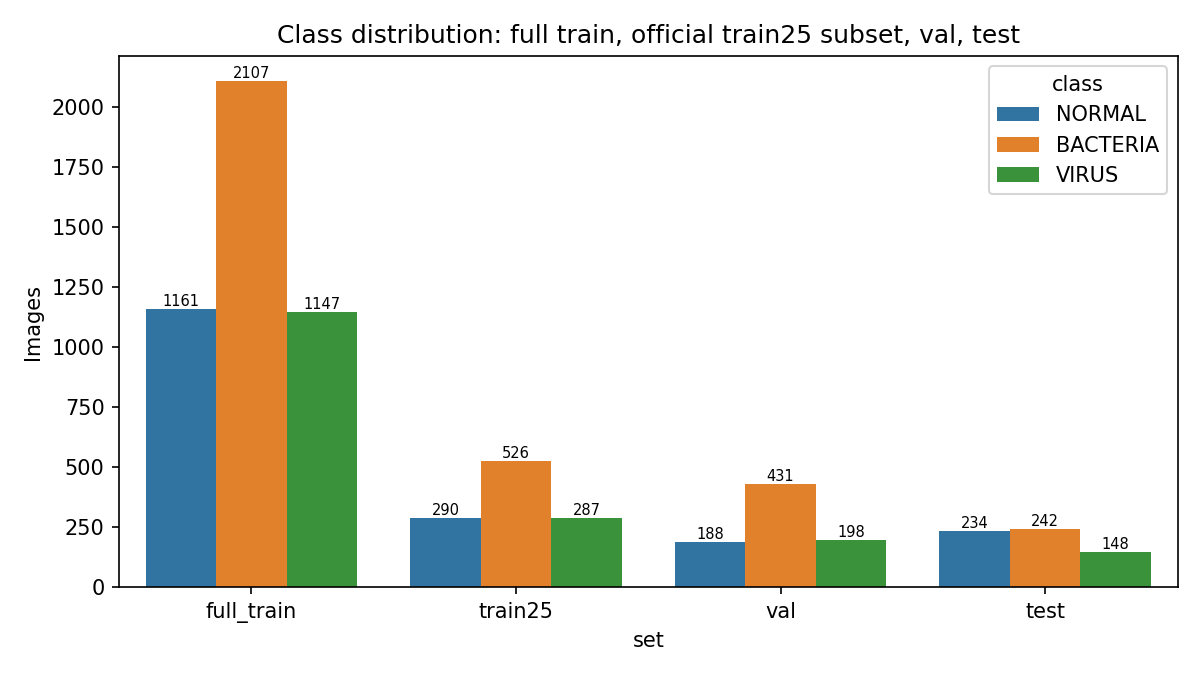

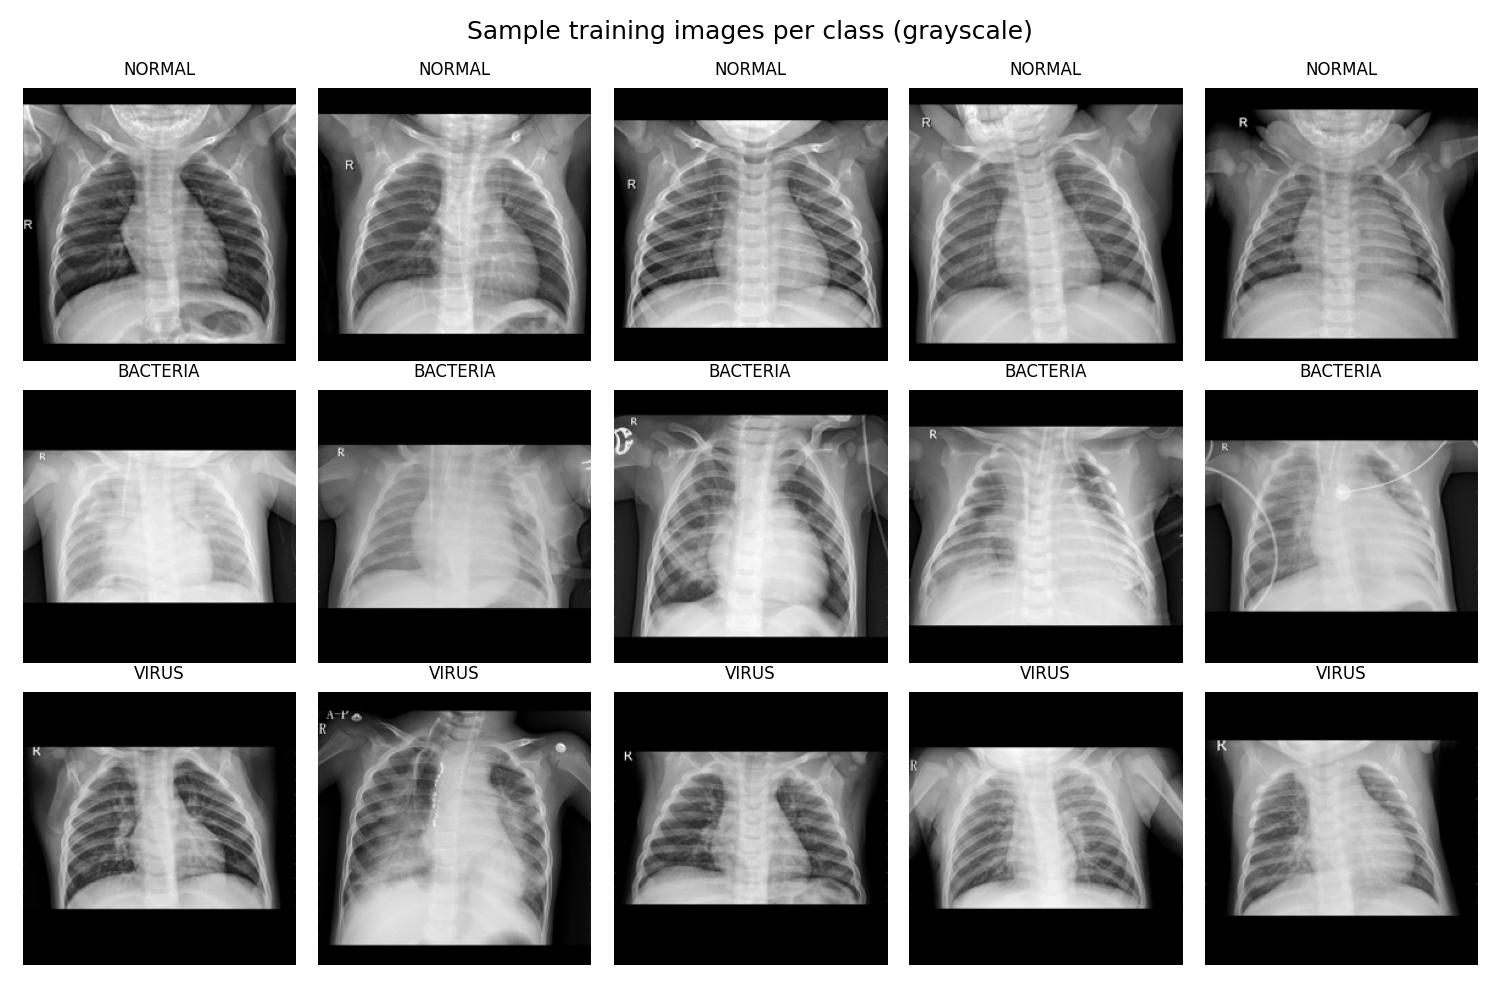

In [4]:
from IPython.display import Image, display
display(Image(filename="results/figures/class_distribution.png"))
display(Image(filename="results/figures/samples_by_class.png"))

The official subset is stored at `data/splits/train25_seed42.json`:

- 1103 images
- NORMAL 290, BACTERIA 526, VIRUS 287
- maximum class-proportion difference from the full training split: 0.0004

The subset is reused by every reported experiment. Do not regenerate it.